# HazeCast SG: PM2.5 at +6, +12 and +24 hours

Run in the project Docker kernel after copying the five supplied Python files into `src/hazecast`. Restart the kernel first. Predictions represent the reading at each future hour, not a period average. Training compares all six candidates independently for each target and horizon.


In [3]:
import sys, os, logging
from pathlib import Path

# Makes `import hazecast...` work whether this notebook is run from inside
# the Docker container (PYTHONPATH already set, see docker/pipeline.Dockerfile)
# or from a local `jupyter lab` with no PYTHONPATH set at all.
repo_root = Path.cwd()
if not (repo_root / "src" / "hazecast").exists():
    # notebook launched from notebooks/ instead of the repo root
    repo_root = repo_root.parent
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Jupyter sets the kernel's cwd to wherever the .ipynb file lives (this
# notebook's own folder, when opened via JupyterLab's file browser) --
# NOT the repo root. That silently breaks anything that writes to a
# relative path, most importantly MLflow's default local artifact store
# (`./mlruns/`), which would otherwise land inside notebooks/ instead of
# next to data/ and mlflow.db. Pin cwd to the repo root explicitly so
# every relative path in every stage below resolves the same way it does
# when running `python -m hazecast....` from the repo root.
os.chdir(repo_root)

logging.basicConfig(level=logging.INFO, force=True)

import hazecast
print("hazecast package OK, repo root:", repo_root)

hazecast package OK, repo root: /app/src


In [4]:
import pandas as pd
import hazecast.config as config
import hazecast.hourly_model as hourly
import hazecast.score as scoring

print("Config:", config.__file__)
print("Hourly model:", hourly.__file__)
print("Scoring:", scoring.__file__)
print(config.MODEL_CANDIDATES)
assert config.HOURLY_HORIZONS == [6, 12, 24]
assert len(config.MODEL_CANDIDATES) == 6


Config: /app/src/hazecast/config.py
Hourly model: /app/src/hazecast/hourly_model.py
Scoring: /app/src/hazecast/score.py
('persistence', 'ridge', 'random_forest', 'xgboost', 'lightgbm', 'xgboost_q85')


## Refresh hourly gold from the existing silver tables
Run after upstream silver tables are refreshed. The unchanged feature builder already supplies the required hourly readings.


In [5]:
from hazecast.silver_to_gold import build_gold_hourly, write_gold_hourly

pm25 = pd.read_parquet(config.SILVER_DIR / "pm25.parquet")
weather = pd.read_parquet(config.SILVER_DIR / "weather.parquet")
firms = pd.read_parquet(config.SILVER_DIR / "firms_daily.parquet")
hourly_gold = build_gold_hourly(pm25, weather, firms)
print(write_gold_hourly(hourly_gold))
print(hourly_gold.shape, hourly_gold["date"].min(), hourly_gold["date"].max())


/app/data/gold/hourly_features.parquet
(110015, 63) 2014-04-01 01:00:00 2026-10-18 23:00:00


## Train, compare and select
This can take time: each target and horizon gets a six-candidate forward comparison. It writes evaluation results and the hourly manifest. Daily winners are not reused.


In [7]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "lightgbm>=4.0"
])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 42.7 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


0

In [8]:
import lightgbm 

In [9]:
model_paths = hourly.train_final_hourly_models(hourly_gold)
assert len(model_paths) == 18
model_paths


INFO:hazecast.hourly_model:Published 18 hourly selections for horizons [6, 12, 24]


{('north',
  6): PosixPath('/app/data/models/hourly/north_h6_fe118df617e4430f8f5e3d115f2e1910.joblib'),
 ('south',
  6): PosixPath('/app/data/models/hourly/south_h6_008a4661b4154e699ee75c1129be76ac.joblib'),
 ('east',
  6): PosixPath('/app/data/models/hourly/east_h6_3e38b4d865744a229d5d00e24feb726d.joblib'),
 ('west',
  6): PosixPath('/app/data/models/hourly/west_h6_d7cac985febb4d2289b5b1dcc2e734b0.joblib'),
 ('central',
  6): PosixPath('/app/data/models/hourly/central_h6_e83ce9ac69f34d25824795657a088970.joblib'),
 ('national',
  6): PosixPath('/app/data/models/hourly/national_h6_f1e7c0af9c2e435dbbb8bf39cc606e30.joblib'),
 ('north',
  12): PosixPath('/app/data/models/hourly/north_h12_0035a0b873b944b299d2b043e4c7171a.joblib'),
 ('south',
  12): PosixPath('/app/data/models/hourly/south_h12_571bb2c48d2c4bb49955e042e17859bf.joblib'),
 ('east',
  12): PosixPath('/app/data/models/hourly/east_h12_e6d90fb3936d40a9a646df2c15e00403.joblib'),
 ('west',
  12): PosixPath('/app/data/models/hourly/we

In [10]:
eval_df = pd.read_csv(config.MODELS_DIR / "hourly" / "eval_summary.csv")
display(
    eval_df.loc[eval_df["split"] == "validation_pooled"]
    .pivot(index=["target", "horizon_hours"], columns="model", values=["mae", "rmse", "f2"])
    .round(3)
)
display(eval_df.loc[eval_df["split"] == "final_test",
    ["target", "horizon_hours", "model", "mae", "rmse", "f2", "n_elevated"]])


mae                                           \
model                  lightgbm persistence random_forest  ridge xgboost   
target   horizon_hours                                                     
central  6                4.808       5.705         4.900  4.918   4.805   
         12               5.124       6.221         5.317  5.323   5.130   
         24               5.173       6.182         5.410  5.377   5.253   
east     6                4.937       5.847         5.076  5.066   4.948   
         12               5.272       6.489         5.509  5.458   5.316   
         24               5.304       6.356         5.634  5.558   5.419   
national 6                3.541       3.885         3.679  3.714   3.550   
         12               3.951       4.513         4.249  4.196   3.981   
         24               4.011       4.563         4.383  4.321   4.096   
north    6                4.705       5.247         5.076  4.982   4.761   
         12               5.049       5.830         5.604  5.477   5.123   
         24               5.011       5.550         5.560  5.476   5.115   
south    6                5.137       6.003         5.342  5.310   5.157   
         12               5.442       6.456         5.792  5.698   5.489   
         24               5.408       6.372         5.849  5.769   5.487   
west     6                4.769       5.510         5.172  5.122   4.800   
         12               5.083       5.979         5.701  5.518   5.158   
         24               5.152       5.905         5.791  5.668   5.278   

                                       rmse                                   \
model                  xgboost_q85 lightgbm persistence random_forest  ridge   
target   horizon_hours                                                         
central  6                   7.566    6.528       7.853         6.516  6.558   
         12                  8.424    6.980       8.548         7.444  7.035   
         24                  8.631    7.082       8.650         7.278  7.106   
east     6                   8.009    6.727       8.052         6.735  6.816   
         12                  8.750    7.212       8.925         7.466  7.280   
         24                  9.031    7.312       8.951         7.669  7.412   
national 6                   6.426    4.798       5.451         4.938  5.006   
         12                  7.360    5.341       6.330         6.187  5.598   
         24                  7.599    5.498       6.584         6.142  5.757   
north    6                   9.182    6.291       7.431         6.590  6.546   
         12                 10.105    6.698       8.295         7.846  7.098   
         24                 10.039    6.708       8.030         7.432  7.073   
south    6                   9.238    7.060       8.465         7.107  7.159   
         12                 10.044    7.469       9.126         7.944  7.608   
         24                 10.142    7.531       9.156         8.038  7.699   
west     6                   9.209    6.305       7.728         6.792  6.707   
         12                 10.088    6.720       8.410         7.846  7.174   
         24                 10.223    6.843       8.390         7.874  7.283   

                                                 f2                            \
model                  xgboost xgboost_q85 lightgbm persistence random_forest   
target   horizon_hours                                                          
central  6               6.503       9.024    0.323       0.462         0.390   
         12              6.937       9.991    0.115       0.331         0.211   
         24              7.131      10.169    0.058       0.179         0.145   
east     6               6.705       9.484    0.311       0.464         0.349   
         12              7.210      10.344    0.202       0.279         0.244   
         24              7.420      10.793    0.149       0.290         0.360   
national 6           

,target,horizon_hours,model,mae,rmse,f2,n_elevated
24,north,6,xgboost_q85,8.811599,10.941943,0.737606,286
49,south,6,xgboost_q85,9.899454,12.129495,0.752886,317
74,east,6,xgboost_q85,8.278898,10.356744,0.799550,422
99,west,6,xgboost_q85,7.101945,9.774309,0.797984,453
124,central,6,xgboost_q85,7.802061,10.955932,0.690325,579
149,national,6,xgboost_q85,6.143117,8.387162,0.811531,385
174,north,12,xgboost_q85,9.477109,12.518958,0.570579,292
199,south,12,xgboost_q85,10.898242,15.029854,0.605553,323
224,east,12,xgboost_q85,9.070749,11.971345,0.631271,428
249,west,12,xgboost_q85,8.327225,13.202900,0.661849,459


## Score: 18 forecasts
Future labels are not required. Stale input warnings indicate that upstream features need refreshing; forecast times remain anchored to the actual feature origin.


In [11]:
forecast = scoring.score_latest()
assert len(forecast) == 18
assert forecast.groupby("region").size().eq(3).all()
assert forecast.groupby("horizon_hours").size().to_dict() == {6: 6, 12: 6, 24: 6}
print(scoring.write_forecast(forecast))
display(forecast)
display(forecast.pivot(index="region", columns="horizon_hours", values="forecast_pm25"))


/app/data/gold/latest_hourly_forecast.json


,scored_at,as_of_time,forecast_time,horizon_hours,region,model,forecast_pm25,elevated_flag,feature_age_hours
0,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,north,xgboost_q85,75.9,True,148.63
1,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,south,xgboost_q85,91.8,True,148.63
2,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,east,xgboost_q85,105.4,True,148.63
3,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,west,xgboost_q85,114.0,True,148.63
4,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,central,xgboost_q85,110.7,True,148.63
5,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T05:00:00+08:00,6,national,xgboost_q85,96.0,True,148.63
6,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T11:00:00+08:00,12,north,xgboost_q85,87.7,True,148.63
7,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T11:00:00+08:00,12,south,xgboost_q85,110.4,True,148.63
8,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T11:00:00+08:00,12,east,xgboost_q85,137.9,True,148.63
9,2026-10-22T19:37:38.754501+00:00,2026-10-16T23:00:00+08:00,2026-10-17T11:00:00+08:00,12,west,xgboost_q85,140.8,True,148.63


horizon_hours,6,12,24
region,,,
central,110.7,136.7,136.7
east,105.4,137.9,131.0
national,96.0,129.4,124.7
north,75.9,87.7,74.6
south,91.8,110.4,109.3
west,114.0,140.8,156.7


,as_of_time,forecast_time,region,horizon_hours,model,actual_pm25,predicted_pm25,threshold,split,test_start,train_label_end,n_train
0,2024-04-15 05:00:00+08:00,2024-04-15 11:00:00+08:00,central,6,xgboost_q85,7.0,19.428164,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
1,2024-04-15 06:00:00+08:00,2024-04-15 12:00:00+08:00,central,6,xgboost_q85,7.0,20.942961,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
2,2024-04-15 07:00:00+08:00,2024-04-15 13:00:00+08:00,central,6,xgboost_q85,11.0,18.269106,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
3,2024-04-15 08:00:00+08:00,2024-04-15 14:00:00+08:00,central,6,xgboost_q85,9.0,17.004822,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
4,2024-04-15 09:00:00+08:00,2024-04-15 15:00:00+08:00,central,6,xgboost_q85,4.0,14.518891,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000


{'mae': 7.802060727697384, 'rmse': 10.95593193104258, 'f2': 0.6903248587570622, 'tp': 391, 'fp': 125, 'fn': 188, 'n_test': 21955, 'n_elevated': 579, 'mae_elevated': 30.436933886407775}
Chart saved: /app/reports/central_h6_actual_vs_predicted_20240415_20261017.png


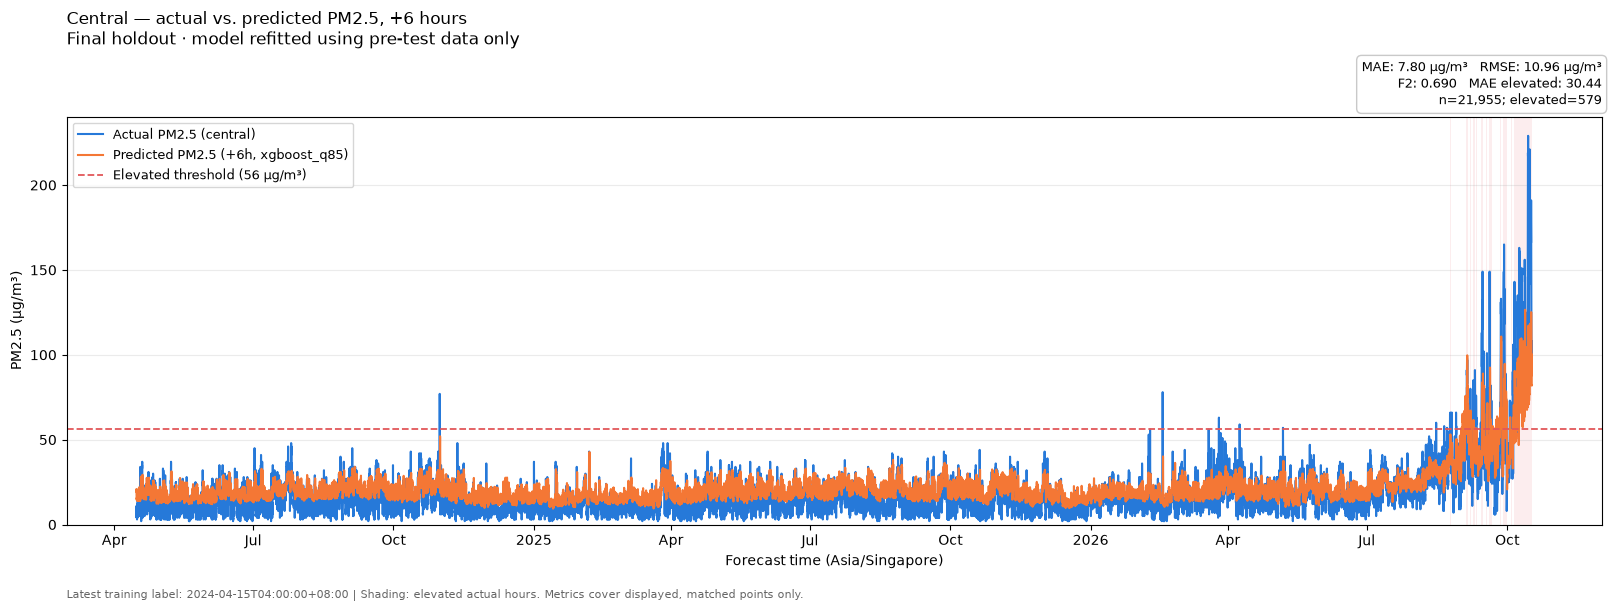

In [15]:
#Historical prediction comparison- Used backtest_selected_models() to refit selected models on pre-test data and compare their predictions against held-out actual values.his validates historical prediction comparison, not live inference using the saved final models.

import pandas as pd
from hazecast.config import GOLD_DIR
from hazecast.hourly_diagnostics import (
    backtest_selected_models,
    plot_actual_vs_predicted,
)

hourly_gold = pd.read_parquet(
    GOLD_DIR / "hourly_features.parquet"
)

# Refits selected models using only pre-test data.
# Does not change production models or archive live forecasts.
predictions = backtest_selected_models(hourly_gold)

display(predictions.head())

fig, metrics, path = plot_actual_vs_predicted(
    predictions,
    target="central",
    horizon=6,
)

print(metrics)
print("Chart saved:", path)

In [ ]:
#Live inference and forecast archiving, not tested because the available hourly features are outdated. Requires current, complete features before archiving live forecasts.

from hazecast.inference import run_inference

saved = run_inference(refresh_gold=True)
display(pd.DataFrame(saved))

In [16]:
#NEA API retrieval — tested.Retrieved historical hourly PM2.5 observations from the NEA API. This checks data retrieval independently of forecast matching.

from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
from hazecast.monitoring import fetch_actuals

yesterday = (
    datetime.now(ZoneInfo("Asia/Singapore")).date()
    - timedelta(days=1)
)

actuals = fetch_actuals(yesterday)
print("Observation records:", len(actuals))
display(pd.DataFrame(actuals).head(12))

Observation records: 144


,observation_time,region,actual_pm25,source,source_updated_at,fetched_at
0,2026-10-24T15:00:00.000000+00:00,north,69.0,NEA_pm25_one_hourly,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
1,2026-10-24T15:00:00.000000+00:00,south,61.0,NEA_pm25_one_hourly,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
2,2026-10-24T15:00:00.000000+00:00,east,66.0,NEA_pm25_one_hourly,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
3,2026-10-24T15:00:00.000000+00:00,west,93.0,NEA_pm25_one_hourly,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
4,2026-10-24T15:00:00.000000+00:00,central,79.0,NEA_pm25_one_hourly,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
5,2026-10-24T15:00:00.000000+00:00,national,73.6,derived_mean_of_five_NEA_regions,2026-10-24T15:45:44.000000+00:00,2026-10-24T16:57:30.035954+00:00
6,2026-10-24T14:00:00.000000+00:00,north,68.0,NEA_pm25_one_hourly,2026-10-24T14:45:39.000000+00:00,2026-10-24T16:57:30.035954+00:00
7,2026-10-24T14:00:00.000000+00:00,south,59.0,NEA_pm25_one_hourly,2026-10-24T14:45:39.000000+00:00,2026-10-24T16:57:30.035954+00:00
8,2026-10-24T14:00:00.000000+00:00,east,82.0,NEA_pm25_one_hourly,2026-10-24T14:45:39.000000+00:00,2026-10-24T16:57:30.035954+00:00
9,2026-10-24T14:00:00.000000+00:00,west,92.0,NEA_pm25_one_hourly,2026-10-24T14:45:39.000000+00:00,2026-10-24T16:57:30.035954+00:00


In [ ]:
#Daily forecast monitoring — Requires genuine forecasts archived by step 2 and actual NEA readings after their forecast target dates have completed.

from hazecast.monitoring import run_monitoring

report = run_monitoring(lookback_days=3)

print("Status:", report["status"])
display(pd.DataFrame(report["summaries"])[
    ["target_date_sgt", "region", "horizon_hours",
     "n_forecasts", "n_matched", "n_pending_actual",
     "mae", "rmse", "f2"]
])